Random Forest Accuracy: 0.8941176470588236
AdaBoost Accuracy: 0.9092436974789916


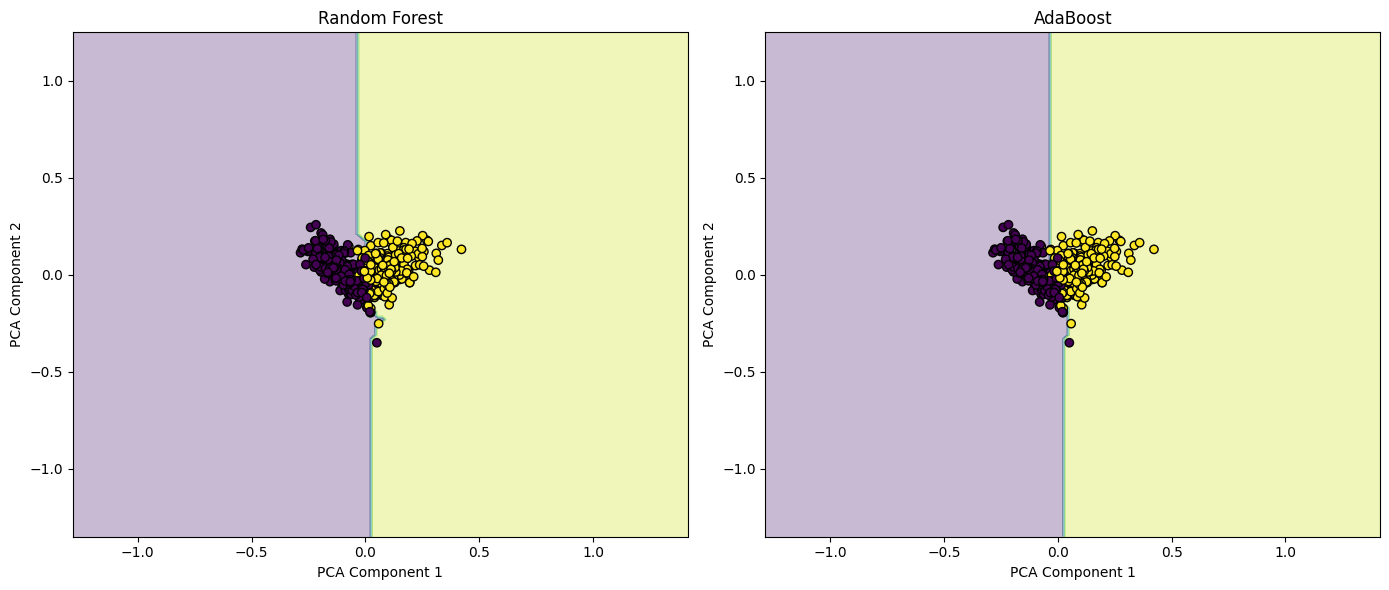

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# Load text dataset
categories = ['rec.sport.baseball', 'sci.space']

data = fetch_20newsgroups(
    subset='all',
    categories=categories,
    remove=('headers', 'footers', 'quotes')
)

X_text = data.data
y = data.target

# Split into training and testing data
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.3,
    random_state=42
)

# Convert text into numerical TF-IDF features
vectorizer = TfidfVectorizer(
    max_features=1000,
    stop_words='english'
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

# Convert sparse matrix to dense matrix for PCA
X_train_dense = X_train.toarray()
X_test_dense = X_test.toarray()

# Reduce dimensionality to 2 dimensions
pca = PCA(n_components=2)

X_train_2d = pca.fit_transform(X_train_dense)
X_test_2d = pca.transform(X_test_dense)

# Train Random Forest
rf_clf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_clf.fit(X_train_2d, y_train)

# Train AdaBoost
ada_clf = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

ada_clf.fit(X_train_2d, y_train)

# Make predictions
rf_pred = rf_clf.predict(X_test_2d)
ada_pred = ada_clf.predict(X_test_2d)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)
ada_accuracy = accuracy_score(y_test, ada_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("AdaBoost Accuracy:", ada_accuracy)


# Function to plot decision boundaries
def plot_decision_boundaries(clf, X, y, ax, title):

    h = 0.02

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )

    Z = clf.predict(
        np.c_[xx.ravel(), yy.ravel()]
    )

    Z = Z.reshape(xx.shape)

    ax.contourf(
        xx,
        yy,
        Z,
        alpha=0.3
    )

    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolor='k',
        marker='o'
    )

    ax.set_title(title)
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")


# Create plots
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest
plot_decision_boundaries(
    rf_clf,
    X_test_2d,
    y_test,
    axs[0],
    'Random Forest'
)

# AdaBoost
plot_decision_boundaries(
    ada_clf,
    X_test_2d,
    y_test,
    axs[1],
    'AdaBoost'
)

plt.tight_layout()
plt.show()